Autores: Pedro Agrelo Márquez, Sneshanka Blanca Andrés Ochoa Grupo de prácticas: Grupo 15

# Preprocesado de EuroSAT

Este cuaderno lee las imágenes de EuroSAT desde disco, hace la partición entrenamiento / validación / test y guarda los tres conjuntos en archivos .npz.

In [18]:
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import keras

SEMILLA = 123
random.seed(SEMILLA); np.random.seed(SEMILLA)

DATA_DIR = Path("../../EuroSAT_RGB")      # dataset (Cambiar si se cambia la ubicacion del dataset)
OUT_DIR = Path("eurosat_split")     # carpeta donde se guarda el split
OUT_DIR.mkdir(exist_ok=True)

### 1. Carga de las imágenes

Se utiliza shuffle false para poder reproducir la ejecución y batch size none para cargar las imagenes de una en una. Se guardan como uint8 para ahorrar espacio.

In [19]:
dataset = keras.utils.image_dataset_from_directory(DATA_DIR, image_size=(64, 64), color_mode="rgb", batch_size=None, shuffle=False)

print("Clases:", dataset.class_names)

X = np.stack([x.numpy().astype("uint8") for x, _ in dataset])
y = np.array([label for _, label in dataset])
print("X (imágenes):", X.shape)
print("y (labels):", y.shape)

Found 27000 files belonging to 10 classes.
Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
X (imágenes): (27000, 64, 64, 3)
y (labels): (27000,)


### 2. Distribución de clases

AnnualCrop             3000
Forest                 3000
HerbaceousVegetation   3000
Highway                2500
Industrial             2500
Pasture                2000
PermanentCrop          2500
Residential            3000
River                  2500
SeaLake                3000


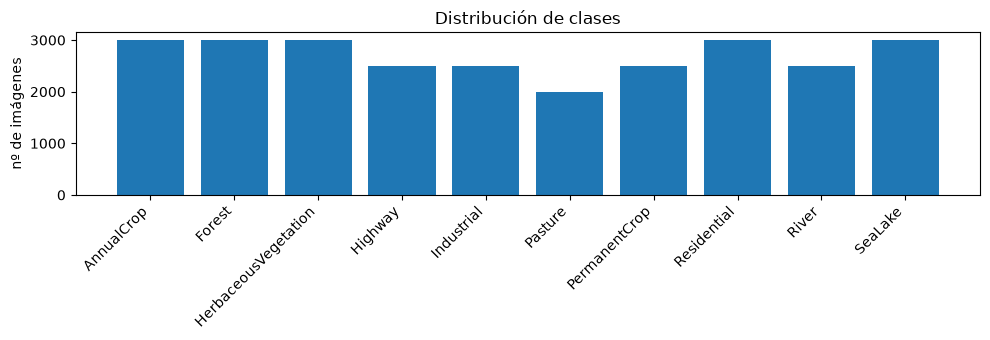

In [20]:
counts = np.bincount(y)
for i, c in enumerate(dataset.class_names):
    print(f"{c:22s} {counts[i]}")

plt.figure(figsize=(10, 3.5))
plt.bar(dataset.class_names, counts)
plt.xticks(rotation=45, ha="right"); plt.ylabel("nº de imágenes"); plt.title("Distribución de clases")
plt.tight_layout(); plt.show()


El dataset está ligeramente desbalanceado (entre 2000 y 3000 imágenes por clase). Por eso la partición se hace de forma estratificada: cada clase se reparte 70/15/15 de forma independiente, de modo que train, validación y test mantienen las mismas proporciones de clases.

### 3. Partición estratificada train / val / test

In [ ]:
def particion_estratificada(etiquetas, proporciones=(0.70, 0.15, 0.15), semilla=SEMILLA):
    generador_aleatorio = np.random.default_rng(semilla)
    
    indices_train = []
    indices_val   = []
    indices_test  = []
    
    proporcion_train, proporcion_val, _ = proporciones
    
    for clase in np.unique(etiquetas):
        # Índices de todas las imágenes de esta clase, mezclados al azar
        indices_de_la_clase = np.where(etiquetas == clase)[0]
        indices_mezclados   = generador_aleatorio.permutation(indices_de_la_clase)
        
        # Calculamos cuántas imágenes de esta clase van a cada conjunto
        num_para_train = int(round(len(indices_mezclados) * proporcion_train))
        num_para_val   = int(round(len(indices_mezclados) * proporcion_val))
        
        # Cortamos el array mezclado en tres trozos
        indices_train.append(indices_mezclados[:num_para_train])
        indices_val.append(indices_mezclados[num_para_train : num_para_train + num_para_val])
        indices_test.append(indices_mezclados[num_para_train + num_para_val :])
        
    # Juntamos las clases y volvemos a mezclar para que no queden agrupadas
    train_final = generador_aleatorio.permutation(np.concatenate(indices_train))
    val_final   = generador_aleatorio.permutation(np.concatenate(indices_val))
    test_final  = generador_aleatorio.permutation(np.concatenate(indices_test))
    
    return train_final, val_final, test_final


indices_train, indices_val, indices_test = particion_estratificada(y)
X_train, y_train = X[indices_train], y[indices_train]
X_val,   y_val   = X[indices_val],   y[indices_val]
X_test,  y_test  = X[indices_test],  y[indices_test]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (18900, 64, 64, 3) | Val: (4050, 64, 64, 3) | Test: (4050, 64, 64, 3)


In [ ]:
# Proporción de cada clase en cada conjunto
print(f"{'clase':22s}{'total':>7s}{'train':>8s}{'val':>7s}{'test':>7s}")
for i, c in enumerate(dataset.class_names):
    print(f"{c:22s}{counts[i]:>7d}{np.sum(y_train == i):>8d}{np.sum(y_val == i):>7d}{np.sum(y_test == i):>7d}")

clase                   total   train    val   test
AnnualCrop               3000    2100    450    450
Forest                   3000    2100    450    450
HerbaceousVegetation     3000    2100    450    450
Highway                  2500    1750    375    375
Industrial               2500    1750    375    375
Pasture                  2000    1400    300    300
PermanentCrop            2500    1750    375    375
Residential              3000    2100    450    450
River                    2500    1750    375    375
SeaLake                  3000    2100    450    450


### 4. Guardado 

Se guardan las imágenes como uint8 y las etiquetas como enteros. Se guardan sin normalizar ni aplanar a propósito para poder reutilizar el preprocesado entre prácticas.

In [24]:
np.savez_compressed(OUT_DIR / "train.npz", X=X_train, y=y_train)
np.savez_compressed(OUT_DIR / "val.npz",   X=X_val,   y=y_val)
np.savez_compressed(OUT_DIR / "test.npz",  X=X_test,  y=y_test)
np.save(OUT_DIR / "class_names.npy", np.array(dataset.class_names))